# OFDM: инженерия многочастотного сигнала

OFDM — общий предок почти всего в этой серии. LTE и NR, Wi-Fi, DVB-T, DAB, ADSL/VDSL, PLC и DroneID у DJI — это OFDM. OTFS, AFDM, OCDM и OTSM определяются как «OFDM плюс ещё одно преобразование». Основа — одна идея: разбить широкую полосу на $N$ узких поднесущих, каждая настолько узкая, что канал на ней плоский:
$$s[n]=\frac1{\sqrt N}\sum_{k}X_k\,e^{\,j2\pi kn/N},\qquad n=-N_{CP},\dots,N-1 .$$
Циклический префикс делает линейную свёртку с каналом круговой, и FFT диагонализует её: $Y_k=H_kX_k+W_k$. Эквалайзер — одно комплексное деление на поднесущую.

Базовая цепочка — CP против ISI, пилоты CRS, доплер и BER в замираниях, PAPR против SC-FDMA — разобрана в `lte_sim`. Здесь — то, что делает OFDM **реальной системой**, а не формулой. Каждый раздел — отдельное обязательство, которое OFDM берёт на себя ради простого эквалайзера:

1. **Ортогональность**: поднесущие — sinc в частоте, FFT — банк фильтров; окно FFT свободно двигается внутри CP.
2. **Спектр**: прямоугольное окно даёт хвосты $1/f^2$; защитные поднесущие, WOLA, f-OFDM.
3. **Синхронизация**: метрика Шмидла–Кокса, ICI от остаточного сдвига частоты, точность оценки.
4. **Радиотракт**: фазовый шум (CPE и ICI), IQ-дисбаланс (зеркальная поднесущая).
5. **Пик-фактор и усилитель**: SLM, клиппинг с фильтрацией, EVM и ACLR против запаса по мощности.
6. **Побитовая загрузка** (DMT, ADSL/VDSL): водозаполнение и зазор до Шеннона.
7. **Нумерология**: какой $\Delta f$ выбрать под разброс задержек и доплер (5G NR, $\mu=0\dots4$).

Почти в каждом разделе — формула и проверка моделированием; числа «теория / измерено» печатаются.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc, j0
from scipy.signal import welch
from scipy.optimize import brentq

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N_FFT = 256            # размер FFT
N_USED = 180           # занятые поднесущие без DC — как несущая LTE 3 МГц
N_CP = 18              # циклический префикс, отсчётов (7 %)
DF = 15e3              # разнос поднесущих, Гц
OS = 4                 # передискретизация для спектра и PAPR
QAM_M = 16
SYMS = 400             # символов OFDM для спектров и статистики

rng = np.random.default_rng(SEED)

## Примитивы: QAM с кодом Грея, модулятор/демодулятор OFDM с передискретизацией, EVM, СПМ

In [2]:
FS = N_FFT * DF; T = 1 / DF
USED = np.r_[-(N_USED // 2):0, 1:N_USED // 2 + 1]      # индексы бинов (отрицательные — ниже несущей)
ALL = np.arange(N_FFT)
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qam_const(Mq):
    """квадратная QAM с кодом Грея; метка = индекс точки, единичная средняя мощность"""
    m = int(round(np.sqrt(Mq))); k = int(np.log2(m))
    pam = np.empty(m); pam[np.arange(m) ^ (np.arange(m) >> 1)] = 2 * np.arange(m) - m + 1
    lab = np.arange(Mq); c = pam[lab >> k] + 1j * pam[lab & (m - 1)]
    return c / np.sqrt(np.mean(np.abs(c) ** 2))

def qam_demap(z, c):
    zf = z.ravel(); out = np.empty(zf.size, int)
    for i in range(0, zf.size, 20000):
        out[i:i + 20000] = np.argmin(np.abs(zf[i:i + 20000, None] - c[None]), 1)
    return out.reshape(z.shape)

def ofdm_mod(X, n=N_FFT, ncp=N_CP, os=1, bins=USED):
    """X (S, len(bins)) → (S, os·(n+ncp)): каждая строка — символ с CP; средняя мощность отсчёта 1"""
    nf = os * n; G = np.zeros(X.shape[:-1] + (nf,), complex); G[..., bins % nf] = X
    x = np.fft.ifft(G, axis=-1) * nf / np.sqrt(len(bins))
    return np.concatenate([x[..., nf - os * ncp:], x], -1)

def ofdm_demod(y, n=N_FFT, ncp=N_CP, os=1, bins=USED, start=None):
    """y (S, os·(n+ncp)) → (S, len(bins)); окно FFT начинается после CP (или в start)"""
    nf = os * n; s = os * ncp if start is None else start
    return np.fft.fft(y[..., s:s + nf], axis=-1)[..., bins % nf] * np.sqrt(len(bins)) / nf

def evm_db(z, x):
    return 10 * np.log10(np.mean(np.abs(z - x) ** 2) / np.mean(np.abs(x) ** 2) + 1e-30)

def psd(x, fs):
    """СПМ методом Уэлча; ось — в единицах Δf; нормировка: 0 дБ — среднее в полосе"""
    f, p = welch(x, fs=fs, nperseg=4096 * fs // FS // 4 * 4, return_onesided=False, window="hann")
    i = np.argsort(f); f, p = f[i] / DF, p[i]
    return f, p / np.mean(p[np.abs(f) < N_USED / 2 - 5])

def band_power(f, p, lo, hi):
    m = (f >= lo) & (f <= hi); return np.sum(p[m])

C16 = qam_const(QAM_M)

# самопроверки
for Mq in (4, 16, 64, 256, 1024):
    c = qam_const(Mq); d = np.abs(c[:, None] - c[None]); dmin = d[d > 1e-9].min()
    nb = np.argwhere(np.abs(d - dmin) < 1e-9)
    assert abs(np.mean(np.abs(c) ** 2) - 1) < 1e-12 and all(bin(a ^ b).count("1") == 1 for a, b in nb), Mq
_X = C16[rng.integers(0, 16, (3, N_USED))]
assert np.allclose(ofdm_demod(ofdm_mod(_X)), _X) and np.allclose(ofdm_demod(ofdm_mod(_X, os=OS), os=OS), _X)
assert abs(np.mean(np.abs(ofdm_mod(C16[rng.integers(0, 16, (200, N_USED))])) ** 2) - 1) < 0.02
print(f"FFT {N_FFT}, Δf = {DF/1e3:.0f} кГц, Fs = {FS/1e6:.2f} МГц, символ {T*1e6:.1f} мкс + CP {N_CP/FS*1e6:.2f} мкс; занято {N_USED} поднесущих = {N_USED*DF/1e6:.2f} МГц")

FFT 256, Δf = 15 кГц, Fs = 3.84 МГц, символ 66.7 мкс + CP 4.69 мкс; занято 180 поднесущих = 2.70 МГц


## 1. Ортогональность: почему поднесущие не мешают друг другу
Поднесущая $k$ на окне длины $T=1/\Delta f$ — прямоугольный импульс, умноженный на $e^{j2\pi k\Delta f t}$. Её спектр — $\mathrm{sinc}\big((f-k\Delta f)T\big)$: широкий, перекрывается с соседями, но **пик каждой поднесущей попадает в нули всех остальных**. Поэтому выборка спектра в точках $k\Delta f$ (это и есть FFT) разделяет их без потерь, хотя спектры перекрываются. Плотность решётки $\Delta f\cdot T=1$ — максимально возможная для ортогонального базиса. По теореме Балиана–Лоу при такой плотности импульс не может быть хорошо локализован и во времени, и в частоте одновременно: прямоугольник компактен во времени и расплывчат в частоте. Отсюда раздел 2.

Средний график показывает FFT как банк фильтров: бин 0 откликается на тон частоты $f$ ядром Дирихле ≈ sinc. Боковой лепесток −13.3 дБ: тон между бинами (CFO, раздел 3) просачивается во все соседние.

Справа — свобода, которую даёт CP. Канал из трёх лучей длиной 6 отсчётов, CP 18. Окно FFT можно начать на 0…12 отсчётов раньше номинала: в окне по-прежнему целый период каждого луча, и сдвиг превращается в линейную фазу $e^{-j2\pi k\delta/N}$, которую поглощает оценка канала. За пределами этого плато в окно попадают $D$ «чужих» отсчётов соседнего символа. Желаемая часть ослабляется до $(N-D)/N$, а помеха равна
$$\frac DN+\frac{D(N-D)}{N^2}\approx\frac{2D}N\quad(\text{ISI + ICI}).$$
Эта же формула работает в разделе 7 для лучей длиннее CP.

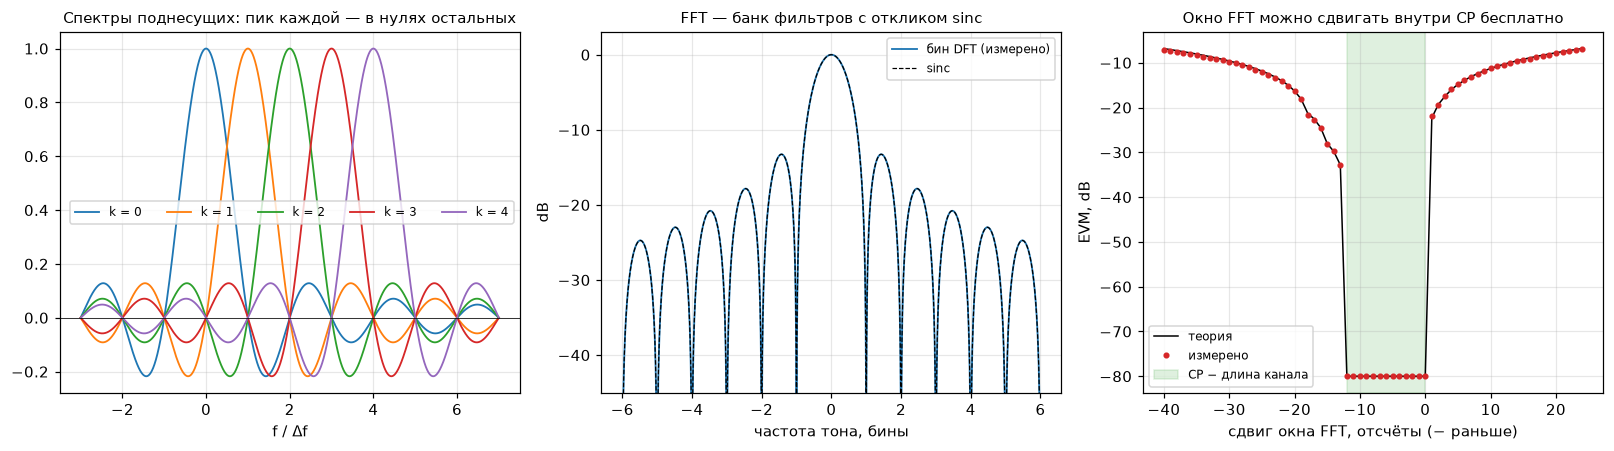

Матрица Грама 256 поднесущих на окне T: max|недиагональный| = 2.2e-14
Первый боковой лепесток бина DFT: -13.26 дБ (sinc: −13.26 дБ); спад лепестков 6 дБ/октаву — отсюда медленный спад спектра OFDM в разделе 2
  сдвиг -12: EVM измерено  -99.0 дБ, теория  -99.0 дБ
  сдвиг  -5: EVM измерено  -99.0 дБ, теория  -99.0 дБ
  сдвиг  +0: EVM измерено  -99.0 дБ, теория  -99.0 дБ
  сдвиг  +2: EVM измерено  -19.5 дБ, теория  -19.3 дБ
  сдвиг  +8: EVM измерено  -12.5 дБ, теория  -12.4 дБ
  сдвиг -25: EVM измерено  -12.1 дБ, теория  -11.9 дБ


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
f = np.linspace(-3, 7, 2001)
for k in range(5):
    ax[0].plot(f, np.sinc(f - k), lw=1.2, label=f"k = {k}")
ax[0].axhline(0, color="k", lw=0.5); ax[0].set_xlabel("f / Δf"); ax[0].legend(fontsize=8, ncol=5)
ax[0].set_title("Спектры поднесущих: пик каждой — в нулях остальных", fontsize=10)

# бин DFT как фильтр: отклик бина 0 на тон с частотой f
fr = np.linspace(-6, 6, 4801); n = np.arange(N_FFT)
resp = np.abs(np.exp(2j * np.pi * np.outer(fr, n) / N_FFT).mean(1))
ax[1].plot(fr, 20 * np.log10(resp + 1e-9), "C0", lw=1.2, label="бин DFT (измерено)")
ax[1].plot(fr, 20 * np.log10(np.abs(np.sinc(fr)) + 1e-9), "k--", lw=0.8, label="sinc")
ax[1].set_ylim(-45, 3); ax[1].set_xlabel("частота тона, бины"); ax[1].set_ylabel("dB"); ax[1].legend(fontsize=8)
ax[1].set_title("FFT — банк фильтров с откликом sinc", fontsize=10)
sl = 20 * np.log10(resp[(np.abs(fr) > 1) & (np.abs(fr) < 2)].max())

# смещение окна FFT в канале с тремя лучами
h_d = np.array([0, 3, 6]); h_a = np.array([1, 0.5, 0.3]) * np.exp(1j * np.array([0, 1.3, -2.1]))
h = np.zeros(h_d.max() + 1, complex); h[h_d] = h_a
S1 = 120; L = N_FFT + N_CP
X = C16[rng.integers(0, 16, (S1, N_FFT))]
rx = np.convolve(ofdm_mod(X, bins=ALL).ravel(), h)[:S1 * L]
offs = np.arange(-40, 25); ev_m, ev_t = [], []
P = np.abs(h_a) ** 2
for o in offs:
    st = np.arange(1, S1 - 1) * L + N_CP + o
    Y = np.fft.fft(rx[st[:, None] + np.arange(N_FFT)], axis=1) / np.sqrt(N_FFT)
    Hk = np.sum(Y * X[1:-1].conj(), 0) / np.sum(np.abs(X[1:-1]) ** 2, 0)       # лучший коэффициент на бин
    ev_m.append(np.sum(np.abs(Y - Hk * X[1:-1]) ** 2) / np.sum(np.abs(Hk * X[1:-1]) ** 2))
    D = np.maximum(0, o - h_d) if o > 0 else np.maximum(0, -o - (N_CP - h_d))          # «чужих» отсчётов в окне для каждого луча
    D = np.broadcast_to(D, h_d.shape)
    Sd = np.sum(P * ((N_FFT - D) / N_FFT) ** 2); ev_t.append((P.sum() - Sd) / Sd)
ev_m, ev_t = 10 * np.log10(np.array(ev_m) + 1e-16), 10 * np.log10(np.array(ev_t) + 1e-16)
ax[2].plot(offs, np.maximum(ev_t, -80), "k-", lw=1, label="теория")
ax[2].plot(offs, np.maximum(ev_m, -80), "C3o", ms=3, label="измерено")
ax[2].axvspan(-(N_CP - h_d.max()), 0, color="C2", alpha=0.15, label="CP − длина канала")
ax[2].set_xlabel("сдвиг окна FFT, отсчёты (− раньше)"); ax[2].set_ylabel("EVM, dB"); ax[2].legend(fontsize=8)
ax[2].set_title("Окно FFT можно сдвигать внутри CP бесплатно", fontsize=10)
plt.tight_layout(); plt.show()

G = np.exp(2j * np.pi * np.outer(ALL, n) / N_FFT) / N_FFT
G = G @ G.conj().T * N_FFT
print(f"Матрица Грама 256 поднесущих на окне T: max|недиагональный| = {np.abs(G - np.eye(N_FFT)).max():.1e}")
print(f"Первый боковой лепесток бина DFT: {sl:.2f} дБ (sinc: −13.26 дБ); спад лепестков 6 дБ/октаву — отсюда медленный спад спектра OFDM в разделе 2")
for o in (-12, -5, 0, 2, 8, -25):
    i = list(offs).index(o)
    print(f"  сдвиг {o:+3d}: EVM измерено {max(ev_m[i], -99):6.1f} дБ, теория {max(ev_t[i], -99):6.1f} дБ")

## 2. Спектр и внеполосное излучение
Символ с CP — прямоугольный импульс длины $T+T_{CP}$, поэтому спектр сигнала — сумма $\sum_k\mathrm{sinc}^2\big((f-k\Delta f)(T+T_{CP})\big)$, а хвосты спадают всего как $1/f^2$ (6 дБ на октаву на амплитуду, 20 дБ на декаду по мощности). Измеренный ACLR (мощность в соседнем канале через 3 МГц относительно своей) совпадает с теорией: около −33 дБ. Для LTE требуется −45 дБ, для Wi-Fi спектральная маска ещё жёстче на краях. Три лекарства:

* **Защитные поднесущие** — 75 из 256 бинов пусты (29 %): хвосты успевают спасть до соседа. Лекарство дорогое — это прямая потеря полосы.
* **WOLA** (windowed overlap-add): края символа сглаживаются приподнятым косинусом длины $W$, соседние символы перекрываются внутри CP. Спектр начинает спадать как $1/f^{4}$+, ACLR улучшается на ~14 дБ, и в идеальном канале ортогональность не страдает (окно FFT в «чистой» части). Цена — $W$ отсчётов CP уходят на сглаживание, допустимая длина канала уменьшается.
* **f-OFDM** (кандидат для 5G): весь сигнал фильтруется sinc-фильтром с окном длиной в полсимвола. Хвост падает почти отвесно (ACLR ниже −100 дБ, упирается в точность оценки СПМ). Цена — EVM −33 дБ даже без канала: крайние поднесущие попадают на скат фильтра, а хвост фильтра — межсимвольная помеха. Обычно ставят такой же фильтр и в приёмнике.

В NR стандарт не фиксирует способ: требуется маска и EVM, а WOLA, фильтр или их смесь — решение производителя.

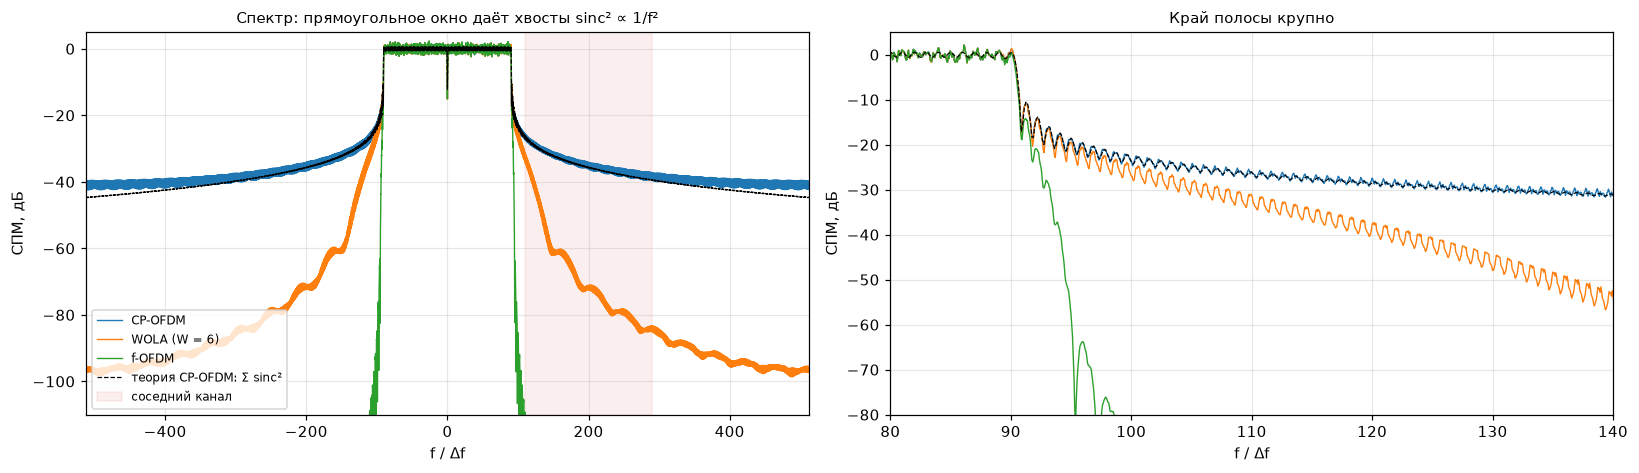

ACLR CP-OFDM: теория -33.5 дБ
  CP-OFDM       : ACLR   -33.1 дБ, EVM в идеальном канале  -99.0 дБ
  WOLA (W = 6)  : ACLR   -46.6 дБ, EVM в идеальном канале  -99.0 дБ
  f-OFDM        : ACLR  -130.2 дБ, EVM в идеальном канале  -33.0 дБ
Защитные поднесущие: 75 из 256 пустые (29% FFT) — первая и самая дорогая мера против хвостов
WOLA «съедает» 6 из 18 отсчётов CP: допустимая длина канала падает до 12


In [4]:
Xs = C16[rng.integers(0, QAM_M, (SYMS, N_USED))]
nf, ncp = OS * N_FFT, OS * N_CP
x_rect = ofdm_mod(Xs, os=OS)

# WOLA: символ продлевается на W отсчётов, края — приподнятый косинус, соседи перекрываются внутри CP
W_WOLA = 6
wo = OS * W_WOLA
ext = np.concatenate([x_rect, x_rect[:, ncp:ncp + wo]], 1)                 # + циклический суффикс
ramp = 0.5 - 0.5 * np.cos(np.pi * (np.arange(wo) + 0.5) / wo)
ext[:, :wo] *= ramp; ext[:, -wo:] *= ramp[::-1]
Lsym = nf + ncp
x_wola = np.zeros(SYMS * Lsym + wo, complex)
for i in range(SYMS):
    x_wola[i * Lsym:i * Lsym + Lsym + wo] += ext[i]
x_wola = x_wola[:SYMS * Lsym]

# f-OFDM: фильтр sinc с окном Ханна длиной в полсимвола
Lf = nf // 2 + 1; fc = (N_USED / 2 + 2) / (OS * N_FFT)
tt = np.arange(Lf) - (Lf - 1) / 2
hf = 2 * fc * np.sinc(2 * fc * tt) * np.hanning(Lf)
x_filt = np.convolve(x_rect.ravel(), hf, mode="same")

sigs = {"CP-OFDM": x_rect.ravel(), f"WOLA (W = {W_WOLA})": x_wola, "f-OFDM": x_filt}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
fth = np.linspace(-OS * N_FFT / 2, OS * N_FFT / 2, 8193)
pth = np.sum(np.sinc((fth[:, None] - USED[None]) * (1 + N_CP / N_FFT)) ** 2, 1)
pth /= np.mean(pth[np.abs(fth) < N_USED / 2 - 5])
ADJ = 200                                                                    # соседний канал через 200 поднесущих (3 МГц)
res = {}
for (name, s), c in zip(sigs.items(), ("C0", "C1", "C2")):
    f, p = psd(s, OS * FS)
    aclr = 10 * np.log10(band_power(f, p, ADJ - N_USED / 2, ADJ + N_USED / 2) / band_power(f, p, -N_USED / 2, N_USED / 2))
    y = s.reshape(SYMS, Lsym)
    ev = evm_db(ofdm_demod(y[2:-2], os=OS), Xs[2:-2])
    res[name] = (aclr, ev)
    for a in ax:
        a.plot(f, 10 * np.log10(p + 1e-20), c, lw=0.9, label=name)
for a in ax:
    a.plot(fth, 10 * np.log10(pth + 1e-20), "k--", lw=0.8, label="теория CP-OFDM: Σ sinc²")
    a.set_xlabel("f / Δf"); a.set_ylabel("СПМ, дБ")
ax[0].axvspan(ADJ - N_USED / 2, ADJ + N_USED / 2, color="C3", alpha=0.08, label="соседний канал")
ax[0].set_xlim(-OS * N_FFT / 2, OS * N_FFT / 2); ax[0].set_ylim(-110, 5); ax[0].legend(fontsize=8, loc="lower left")
ax[0].set_title("Спектр: прямоугольное окно даёт хвосты sinc² ∝ 1/f²", fontsize=10)
ax[1].set_xlim(80, 140); ax[1].set_ylim(-80, 5)
ax[1].set_title("Край полосы крупно", fontsize=10)
plt.tight_layout(); plt.show()

aclr_th = 10 * np.log10(band_power(fth, pth, ADJ - N_USED / 2, ADJ + N_USED / 2) / band_power(fth, pth, -N_USED / 2, N_USED / 2))
print(f"ACLR CP-OFDM: теория {aclr_th:.1f} дБ")
for k, (a, e) in res.items():
    print(f"  {k:14s}: ACLR {a:7.1f} дБ, EVM в идеальном канале {max(e, -99):6.1f} дБ")
print(f"Защитные поднесущие: {N_FFT - N_USED - 1} из {N_FFT} пустые ({(N_FFT - N_USED - 1)/N_FFT:.0%} FFT) — первая и самая дорогая мера против хвостов")
print(f"WOLA «съедает» {W_WOLA} из {N_CP} отсчётов CP: допустимая длина канала падает до {N_CP - W_WOLA}")

## 3. Синхронизация: время и частота
OFDM требует от приёмника знать начало символа с точностью до плато CP (раздел 1) и частоту с точностью до малой доли $\Delta f$. **Преамбула Шмидла–Кокса** (1997, основа преамбул Wi-Fi) занимает только чётные поднесущие. Во времени у неё тогда две одинаковые половины длины $N/2$. Метрика
$$M(d)=\frac{|P(d)|^2}{R(d)^2},\qquad P(d)=\sum_{m=0}^{N/2-1}r^*[d+m]\,r[d+m+N/2]$$
нормирована на энергию и не зависит ни от уровня сигнала, ни от канала. В пределах CP она даёт плато, середина которого и есть оценка времени. Фаза $P$ на плато равна $\pi\varepsilon$, где $\varepsilon$ — сдвиг частоты в долях $\Delta f$. Отсюда дробная часть CFO без всякого поиска (целую часть Шмидл и Кокс берут из второго символа).

Остаточный CFO разрушает ортогональность: окно FFT больше не содержит целого числа периодов. Полезная часть ослабляется до $|f(\varepsilon)|^2=\left|\frac{\sin\pi\varepsilon}{N\sin(\pi\varepsilon/N)}\right|^2$, остальное уходит в ICI:
$$\mathrm{SIR}=\frac{|f(\varepsilon)|^2}{1-|f(\varepsilon)|^2}\approx\frac{3}{(\pi\varepsilon)^2}.$$
Для SIR 30 дБ нужно $\varepsilon<0.017$, то есть 260 Гц при $\Delta f=15$ кГц — это 0.1 ppm на 2.6 ГГц. Кварц даёт 10–20 ppm, поэтому оценка CFO в OFDM обязательна. У одночастотных систем (CDMA, SC-FDE) сдвиг частоты просто медленно вращает созвездие, и его отслеживает петля ФАПЧ.

Точность оценки: $\operatorname{var}\hat\varepsilon=\frac{1/\mathrm{SNR}+1/(2\,\mathrm{SNR}^2)}{\pi^2N/2}$ — усреднение по $N/2$ парам отсчётов. При SNR 10 дБ СКО < 0.01 — остаточный SIR около 36 дБ.

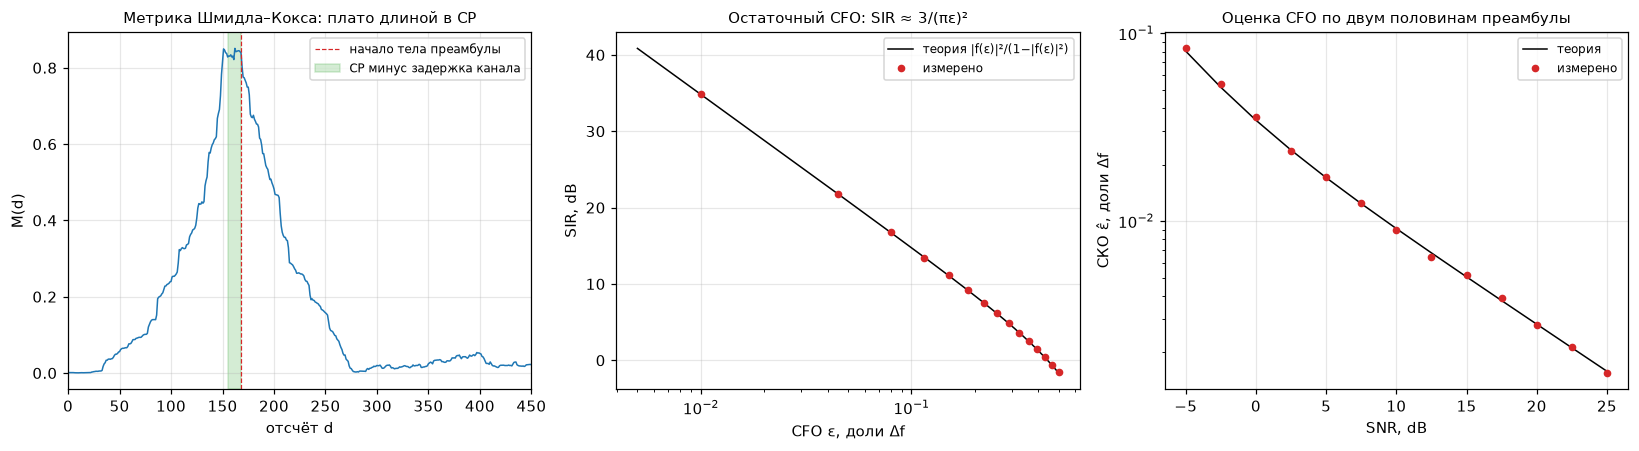

Синхронизация: d̂ = 160 (тело преамбулы с 168, допустимо 155…168); ε̂ = 0.292 при ε = 0.3
  CFO 0.01: SIR измерено  34.8 дБ, теория  34.8 дБ, приближение 3/(πε)²:  34.8 дБ
  CFO 0.11: SIR измерено  13.5 дБ, теория  13.5 дБ, приближение 3/(πε)²:  13.6 дБ
  CFO 0.29: SIR измерено   4.8 дБ, теория   4.8 дБ, приближение 3/(πε)²:   5.6 дБ
СКО ε̂ при SNR 10 дБ: 0.0089 (теория 0.0091) → остаточный SIR ≈ 36 дБ, вклад синхронизации пренебрежим


In [5]:
L2 = N_FFT // 2
EVEN = (USED % 2 == 0)

def sc_preamble(rng):
    """Шмидл–Кокс: заняты только чётные бины → во времени две одинаковые половины"""
    X = np.zeros(N_USED, complex); X[EVEN] = QPSK[rng.integers(0, 4, EVEN.sum())] * np.sqrt(2)
    return ofdm_mod(X[None])[0]

def sc_metric(r):
    P = np.array([np.sum(r[d:d + L2].conj() * r[d + L2:d + 2 * L2]) for d in range(len(r) - 2 * L2)])
    R = np.array([np.sum(np.abs(r[d + L2:d + 2 * L2]) ** 2) for d in range(len(r) - 2 * L2)])
    return np.abs(P) ** 2 / R ** 2, P

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
# кадр: шум, преамбула, 3 символа данных; канал из 3 лучей, CFO 0.3 поднесущей, SNR 10 дБ
EPS, SNR_SYNC, PAD = 0.3, 10, 150
frame = np.concatenate([np.zeros(PAD), sc_preamble(rng), ofdm_mod(C16[rng.integers(0, 16, (3, N_USED))]).ravel()])
hc = np.array([1, 0, 0.6, 0, 0, 0.3]); hc /= np.linalg.norm(hc)
r = np.convolve(frame, hc)[:len(frame)] * np.exp(2j * np.pi * EPS * np.arange(len(frame)) / N_FFT)
r += crandn(r.size, rng) * 10 ** (-SNR_SYNC / 20)
Mt, Pt = sc_metric(r)
d_hat = np.argmax(Mt)
plat = np.where(Mt > 0.9 * Mt.max())[0]
d_hat = (plat[0] + plat[-1]) // 2                          # середина плато 90 % (как у Шмидла и Кокса)
ax[0].plot(Mt, lw=1); ax[0].axvline(PAD + N_CP, color="C3", ls="--", lw=0.8, label="начало тела преамбулы")
ax[0].axvspan(PAD + 5, PAD + N_CP, color="C2", alpha=0.2, label="CP минус задержка канала")
ax[0].set_xlim(PAD - 150, PAD + 300); ax[0].set_xlabel("отсчёт d"); ax[0].set_ylabel("M(d)"); ax[0].legend(fontsize=8)
ax[0].set_title("Метрика Шмидла–Кокса: плато длиной в CP", fontsize=10)
eps_hat = np.angle(Pt[d_hat]) / np.pi

# ICI от CFO: полностью загруженный символ, без шума
eps_g = np.linspace(0.01, 0.5, 15); sir_m = []
nn = np.arange(60 * (N_FFT + N_CP))
for e in eps_g:
    X = C16[rng.integers(0, 16, (60, N_FFT))]
    y = (ofdm_mod(X, bins=ALL).ravel() * np.exp(2j * np.pi * e * nn / N_FFT)).reshape(60, -1)
    Y = ofdm_demod(y, bins=ALL)
    a = np.sum(Y * X.conj(), 1, keepdims=True) / np.sum(np.abs(X) ** 2, 1, keepdims=True)   # общий поворот на символ
    sir_m.append(np.sum(np.abs(a * X) ** 2) / np.sum(np.abs(Y - a * X) ** 2))
fe = lambda e: np.abs(np.sin(np.pi * e) / (N_FFT * np.sin(np.pi * e / N_FFT))) ** 2
ef = np.linspace(0.005, 0.5, 200)
ax[1].semilogx(ef, 10 * np.log10(fe(ef) / (1 - fe(ef))), "k-", lw=1, label="теория |f(ε)|²/(1−|f(ε)|²)")
ax[1].semilogx(eps_g, 10 * np.log10(sir_m), "C3o", ms=4, label="измерено")
ax[1].set_xlabel("CFO ε, доли Δf"); ax[1].set_ylabel("SIR, dB"); ax[1].legend(fontsize=8)
ax[1].set_title("Остаточный CFO: SIR ≈ 3/(πε)²", fontsize=10)

# точность оценки CFO против SNR
snrs = np.arange(-5, 26, 2.5); rmse = []
for s in snrs:
    e_true = rng.uniform(-0.4, 0.4, 400); err = []
    for e in e_true:
        p = sc_preamble(rng)[N_CP:] * np.exp(2j * np.pi * e * np.arange(N_FFT) / N_FFT)
        p += crandn(N_FFT, rng) * 10 ** (-s / 20)
        err.append(np.angle(np.sum(p[:L2].conj() * p[L2:])) / np.pi - e)
    rmse.append(np.sqrt(np.mean(np.square(err))))
sl = 10 ** (snrs / 10)
rm_th = np.sqrt((1 / sl + 1 / (2 * sl ** 2)) / (np.pi ** 2 * L2))
ax[2].semilogy(snrs, rm_th, "k-", lw=1, label="теория"); ax[2].semilogy(snrs, rmse, "C3o", ms=4, label="измерено")
ax[2].set_xlabel("SNR, dB"); ax[2].set_ylabel("СКО ε̂, доли Δf"); ax[2].legend(fontsize=8)
ax[2].set_title("Оценка CFO по двум половинам преамбулы", fontsize=10)
plt.tight_layout(); plt.show()

print(f"Синхронизация: d̂ = {d_hat} (тело преамбулы с {PAD + N_CP}, допустимо {PAD + 5}…{PAD + N_CP}); ε̂ = {eps_hat:.3f} при ε = {EPS}")
for e in (0.02, 0.1, 0.3):
    i = np.argmin(np.abs(eps_g - e))
    print(f"  CFO {eps_g[i]:.2f}: SIR измерено {10*np.log10(sir_m[i]):5.1f} дБ, теория {10*np.log10(fe(eps_g[i])/(1-fe(eps_g[i]))):5.1f} дБ, приближение 3/(πε)²: {10*np.log10(3/(np.pi*eps_g[i])**2):5.1f} дБ")
i10 = list(snrs).index(10)
print(f"СКО ε̂ при SNR 10 дБ: {rmse[i10]:.4f} (теория {rm_th[i10]:.4f}) → остаточный SIR ≈ {10*np.log10(3/(np.pi*rmse[i10])**2):.0f} дБ, вклад синхронизации пренебрежим")

## 4. Радиотракт: фазовый шум и IQ-дисбаланс
**Фазовый шум.** Генератор с шириной линии $\beta$ — винеровский процесс фазы: приращение за отсчёт имеет дисперсию $2\pi\beta/F_s$. На поднесущей $k$ после FFT
$$Y_k=J_0X_k+\sum_{m\ne k}J_{m-k}X_m,\qquad J_q=\frac1N\sum_n e^{j\varphi[n]}e^{-j2\pi qn/N}.$$
$J_0$ — **общая ошибка фазы** (CPE): одинаковый поворот всех поднесущих символа. Её снимают пилотами (в NR это PT-RS, в Wi-Fi — 4 пилотные поднесущие). Остальное — ICI, шумоподобная и неустранимая простыми средствами:
$$\text{ICI}=1-\mathbb E|J_0|^2=1-\frac1{N^2}\sum_{d}(N-|d|)\,e^{-\pi\beta|d|/F_s}\approx\frac{\pi\beta}{3\,\Delta f}.$$
Важно отношение $\beta/\Delta f$: широкие поднесущие терпят худший генератор. Это главная причина больших $\Delta f$ в миллиметровом диапазоне (раздел 7). Без коррекции фаза за 60 символов уплывает случайно (поэтому левая кривая немонотонна), и созвездие размазывается по кругу.

**IQ-дисбаланс.** Ветви I и Q с разным усилением $g$ и неортогональностью $\phi$ дают $r=\mu s+\nu s^*$, где $\mu=\tfrac{1+ge^{-j\phi}}2$, $\nu=\tfrac{1-ge^{j\phi}}2$. Сопряжение во времени — это зеркало по частоте: $Y_k=\mu X_k+\nu X^*_{-k}$. **Поднесущая $k$ получает помеху с поднесущей $-k$** с ослаблением $\mathrm{IRR}=|\mu|^2/|\nu|^2$. Для 0.4 дБ и 3° это 29 дБ — на грани для 64-QAM и мало для 256-QAM. Компенсация может быть слепой: «правильный» сигнал OFDM имеет $\mathbb E[s^2]=0$, поэтому подбираем $c$ так, чтобы у $z=r-cr^*$ было $\mathbb E[z^2]=0$. Это одно квадратное уравнение, после которого IRR > 70 дБ.

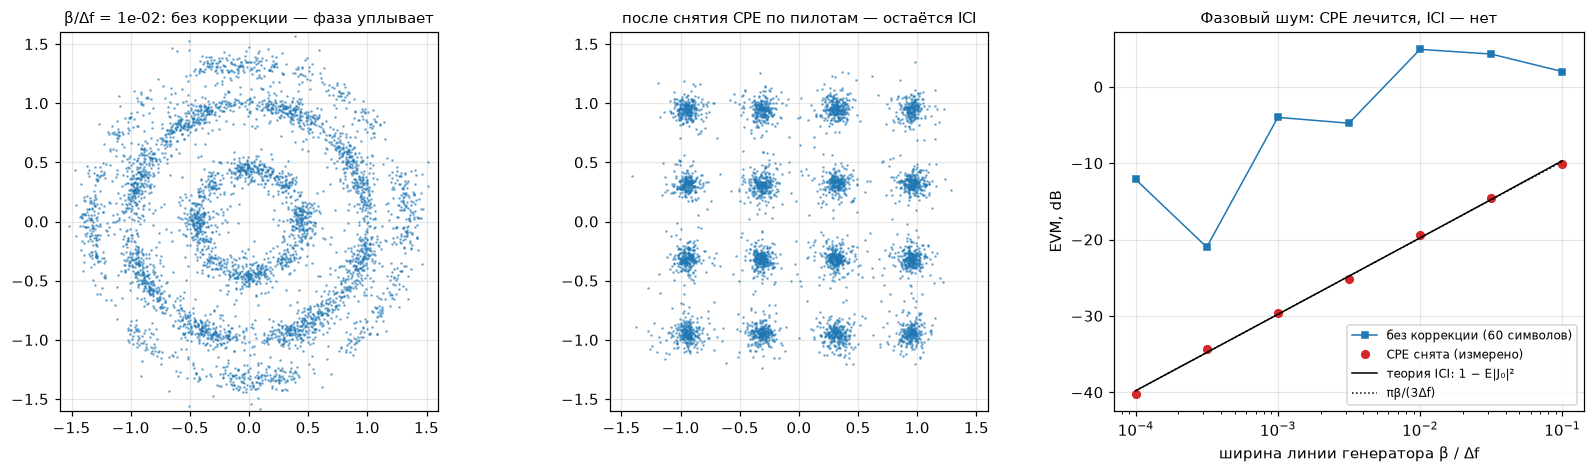

  β/Δf = 1e-04: без коррекции  -12.1 дБ, CPE снята  -40.2 дБ, теория ICI  -39.8 дБ
  β/Δf = 3e-04: без коррекции  -21.0 дБ, CPE снята  -34.3 дБ, теория ICI  -34.8 дБ
  β/Δf = 1e-03: без коррекции   -4.0 дБ, CPE снята  -29.6 дБ, теория ICI  -29.8 дБ
  β/Δf = 3e-03: без коррекции   -4.8 дБ, CPE снята  -25.2 дБ, теория ICI  -24.8 дБ
  β/Δf = 1e-02: без коррекции    4.9 дБ, CPE снята  -19.4 дБ, теория ICI  -19.8 дБ
  β/Δf = 3e-02: без коррекции    4.3 дБ, CPE снята  -14.6 дБ, теория ICI  -14.8 дБ
  β/Δf = 1e-01: без коррекции    2.0 дБ, CPE снята  -10.2 дБ, теория ICI   -9.7 дБ


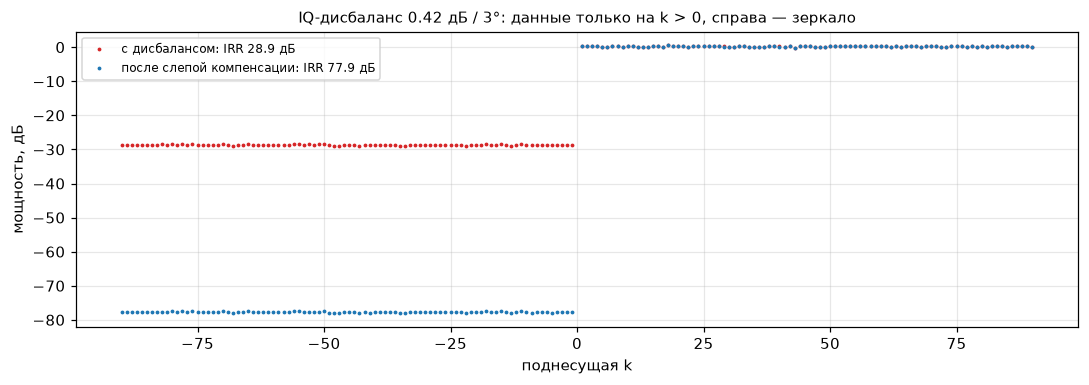

IRR: теория |μ|²/|ν|² = 28.9 дБ, измерено 28.9 дБ; после компенсации 77.9 дБ
При полной загрузке зеркальная помеха = EVM ≈ −IRR = -28.9 дБ: для 64-QAM (нужно ≲ −22 дБ) уже на грани


In [6]:
S4 = 60
PIL = ALL[::8]; DAT = np.setdiff1d(ALL, PIL)                 # 32 пилота для общей фазы (CPE)
br = np.logspace(-4, -1, 7)                                   # β/Δf
e_unc, e_cpe, e_th, snap = [], [], [], {}

def J0sq(N, s2):
    d = np.arange(-(N - 1), N); return np.sum((N - np.abs(d)) * np.exp(-s2 * np.abs(d) / 2)) / N ** 2

for b in br:
    X = C16[rng.integers(0, 16, (S4, N_FFT))]
    x = ofdm_mod(X, bins=ALL).ravel()
    s2 = 2 * np.pi * b / N_FFT                                  # дисперсия приращения фазы за отсчёт: 2πβ/Fs
    phi = np.cumsum(np.sqrt(s2) * rng.standard_normal(x.size))
    Y = ofdm_demod((x * np.exp(1j * phi)).reshape(S4, -1), bins=ALL)
    c = np.sum(Y[:, PIL] * X[:, PIL].conj(), 1, keepdims=True) / np.sum(np.abs(X[:, PIL]) ** 2, 1, keepdims=True)
    Z = Y / c
    e_unc.append(evm_db(Y[:, DAT], X[:, DAT])); e_cpe.append(evm_db(Z[:, DAT], X[:, DAT]))
    J = J0sq(N_FFT, s2); e_th.append(10 * np.log10((1 - J) / J))
    if np.isclose(b, 1e-2, rtol=0.2): snap = (Y[:, DAT], Z[:, DAT], b)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
Yu, Zc, bs = snap
ax[0].plot(Yu.real.ravel()[::3], Yu.imag.ravel()[::3], ".", ms=1.5, alpha=0.5)
ax[0].set_title(f"β/Δf = {bs:.0e}: без коррекции — фаза уплывает", fontsize=10)
ax[1].plot(Zc.real.ravel()[::3], Zc.imag.ravel()[::3], ".", ms=1.5, alpha=0.5)
ax[1].set_title("после снятия CPE по пилотам — остаётся ICI", fontsize=10)
for a in ax[:2]: a.set_aspect("equal"); a.set_xlim(-1.6, 1.6); a.set_ylim(-1.6, 1.6)
ax[2].semilogx(br, e_unc, "C0s-", ms=4, lw=1, label=f"без коррекции ({S4} символов)")
ax[2].semilogx(br, e_cpe, "C3o", ms=5, label="CPE снята (измерено)")
ax[2].semilogx(br, e_th, "k-", lw=1, label="теория ICI: 1 − E|J₀|²")
ax[2].semilogx(br, 10 * np.log10(np.pi * br / 3), "k:", lw=1, label="πβ/(3Δf)")
ax[2].set_xlabel("ширина линии генератора β / Δf"); ax[2].set_ylabel("EVM, dB"); ax[2].legend(fontsize=8)
ax[2].set_title("Фазовый шум: CPE лечится, ICI — нет", fontsize=10)
plt.tight_layout(); plt.show()
for b, u, c_, t in zip(br, e_unc, e_cpe, e_th):
    print(f"  β/Δf = {b:.0e}: без коррекции {u:6.1f} дБ, CPE снята {c_:6.1f} дБ, теория ICI {t:6.1f} дБ")

# IQ-дисбаланс: r = μ·s + ν·s*; поднесущая k получает зеркальную помеху с −k
G_IQ, PH_IQ = 1.05, np.deg2rad(3)
mu = (1 + G_IQ * np.exp(-1j * PH_IQ)) / 2; nu = (1 - G_IQ * np.exp(1j * PH_IQ)) / 2
POS = USED[USED > 0]
X = np.zeros((SYMS, N_USED), complex); X[:, USED > 0] = C16[rng.integers(0, 16, (SYMS, len(POS)))]
s = ofdm_mod(X).ravel()
rr = mu * s + nu * s.conj()
A, B = np.mean(rr ** 2), np.mean(np.abs(rr) ** 2)
cc = (B - np.sqrt(B ** 2 - np.abs(A) ** 2)) / np.conj(A)              # слепая оценка: E[z²] = 0 для «правильного» сигнала
zz = rr - cc * rr.conj()
def irr(sig):
    P = np.mean(np.abs(ofdm_demod(sig.reshape(SYMS, -1))) ** 2, 0)
    return P, 10 * np.log10(P[USED > 0].mean() / P[USED < 0].mean())
Pr, irr_r = irr(rr); Pz, irr_z = irr(zz)
fig, ax = plt.subplots(1, 1, figsize=(10, 3.6))
ax.plot(USED, 10 * np.log10(Pr + 1e-12), "C3.", ms=3, label=f"с дисбалансом: IRR {irr_r:.1f} дБ")
ax.plot(USED, 10 * np.log10(Pz + 1e-12), "C0.", ms=3, label=f"после слепой компенсации: IRR {irr_z:.1f} дБ")
ax.set_xlabel("поднесущая k"); ax.set_ylabel("мощность, дБ"); ax.legend(fontsize=8)
ax.set_title(f"IQ-дисбаланс {20*np.log10(G_IQ):.2f} дБ / {np.rad2deg(PH_IQ):.0f}°: данные только на k > 0, справа — зеркало", fontsize=10)
plt.tight_layout(); plt.show()
print(f"IRR: теория |μ|²/|ν|² = {10*np.log10(abs(mu)**2/abs(nu)**2):.1f} дБ, измерено {irr_r:.1f} дБ; после компенсации {irr_z:.1f} дБ")
print(f"При полной загрузке зеркальная помеха = EVM ≈ −IRR = {-10*np.log10(abs(mu)**2/abs(nu)**2):.1f} дБ: для 64-QAM (нужно ≲ −22 дБ) уже на грани")

## 5. Пик-фактор и усилитель мощности
Сумма многих независимых поднесущих — почти гауссов процесс: $|s|^2$ распределено экспоненциально, и $P(\mathrm{PAPR}>\gamma)\approx1-(1-e^{-\gamma})^{N}$ (выборка по Найквисту; при передискретизации реальные пики на ~0.4 дБ выше). У 180 поднесущих пик 10 дБ встречается в 1 % символов. Усилитель должен пропускать такие пики почти линейно, поэтому работает с **запасом по входу** (IBO) — а КПД класса AB падает примерно вдвое на каждые 3 дБ запаса.

**Модель усилителя Rapp** ($p=2$, только AM/AM): $g(A)=A/(1+A^{2p})^{1/2p}$. По теореме Бусганга выход = $\alpha\cdot$вход + некоррелированное искажение. Для гауссова входа $\alpha$ и мощность искажения считаются интегралом по рэлеевской амплитуде — чёрная линия. Она совпадает с измеренной полной мощностью искажений (крестики). В полосе EVM на ~2 дБ лучше: часть искажений уходит в соседний канал, это и есть рост спектра (правый график).

**Снижение пик-фактора:**
* **SLM** (selected mapping): $U$ вариантов символа с разными фазовыми масками, передаётся лучший; номер маски — побочная информация ($\log_2U$ бит). CCDF становится $[\,\cdot\,]^U$ — 16 вариантов дают −2.7 дБ при 1 %. Чистый выигрыш без искажений, но $U$ IFFT в передатчике.
* **Клиппинг с фильтрацией**: пики срезаются, внеполосные продукты отфильтровываются, 2 итерации. PAPR падает ещё сильнее, но клиппинг — это собственное искажение (EVM −27 дБ уже до усилителя), и при высоком IBO оно становится полом.

Реальное ограничение задаёт **ACLR**, а не EVM: с этим усилителем 8 % EVM достигается уже при IBO 4–6 дБ, а −45 дБ ACLR требует 10–11 дБ. SLM и клиппинг выигрывают по 1 дБ. Поэтому в LTE на аплинке выбрали SC-FDMA (`lte_sim`, раздел 9): у телефона дорог каждый дБ КПД. Базовые станции применяют клиппинг вместе с цифровой предыскажающей коррекцией (DPD).

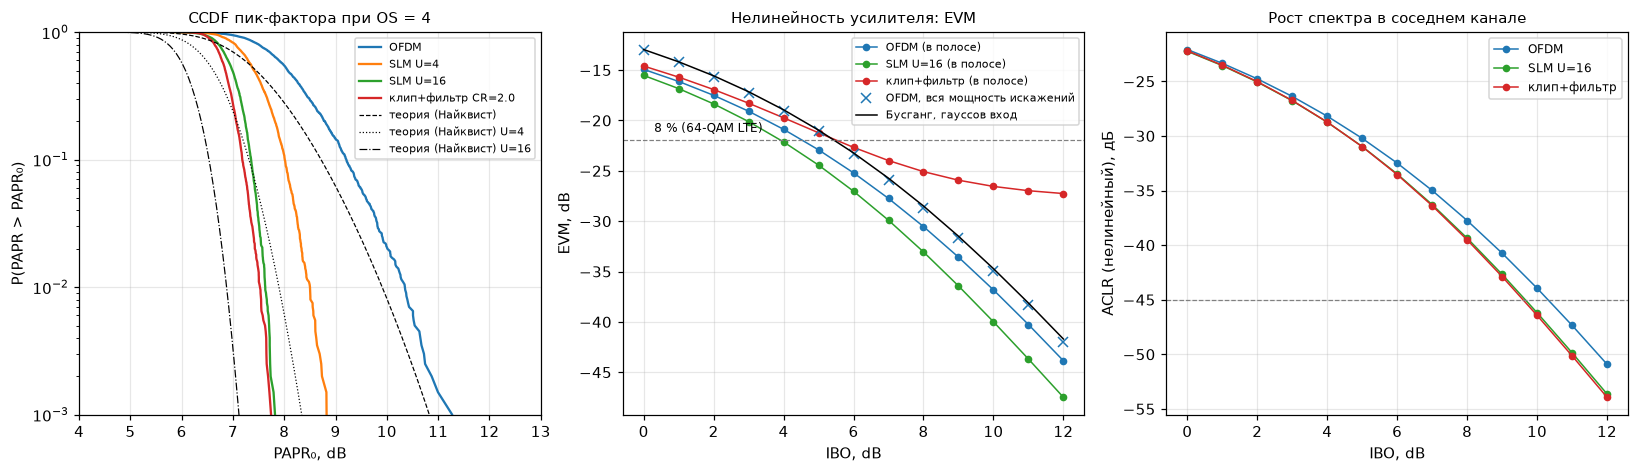

PAPR при P = 1 %: теория (Найквист) 9.9 дБ; OFDM 10.3; SLM U=4 8.5; SLM U=16 7.6; клип+фильтр CR=2.0 7.5
EVM клиппинга самого по себе (до усилителя): -27.4 дБ
При IBO 6 дБ: Бусганг -23.2 дБ, измерено во времени -23.4 дБ, в полосе -25.2 дБ (часть искажений ушла за полосу)
  OFDM          : EVM ≤ 8 % с IBO 5 дБ, ACLR ≤ -45 дБ с IBO 11 дБ → нужен IBO 11 дБ
  SLM U=16      : EVM ≤ 8 % с IBO 4 дБ, ACLR ≤ -45 дБ с IBO 10 дБ → нужен IBO 10 дБ
  клип+фильтр   : EVM ≤ 8 % с IBO 6 дБ, ACLR ≤ -45 дБ с IBO 10 дБ → нужен IBO 10 дБ


In [7]:
S5 = 2000
Xp = C16[rng.integers(0, 16, (S5, N_USED))]
nf = OS * N_FFT

def body(X, phase=None):
    G = np.zeros(X.shape[:-1] + (nf,), complex); G[..., USED % nf] = X if phase is None else X * phase
    return np.fft.ifft(G, axis=-1) * nf / np.sqrt(N_USED)

def papr_db(x):
    return 10 * np.log10(np.max(np.abs(x) ** 2, -1) / np.mean(np.abs(x) ** 2, -1))

x0 = body(Xp)
# SLM: U случайных фазовых масок, передаём лучшую (номер маски — побочная информация)
def slm(X, U, rng):
    ph = QPSK[rng.integers(0, 4, (U, N_USED))] * np.sqrt(2) * np.exp(-1j * np.pi / 4); ph[0] = 1
    cand = body(X[:, None, :] * ph[None])
    best = np.argmin(papr_db(cand), 1)
    return cand[np.arange(len(X)), best], ph[best]
x_slm4, _ = slm(Xp, 4, rng)
x_slm16, ph16 = slm(Xp, 16, rng)
# клиппинг и фильтрация: срезаем пики, возвращаем внеполосное к нулю, 2 итерации
CR = 2.0
def clip_filter(x, cr, it=2):
    for _ in range(it):
        a = np.abs(x); x = np.where(a > cr, x * cr / np.maximum(a, 1e-12), x)
        G = np.fft.fft(x, axis=-1); m = np.zeros(nf, bool); m[USED % nf] = True; G[..., ~m] = 0
        x = np.fft.ifft(G, axis=-1)
    return x
x_cf = clip_filter(x0, CR)

g = np.linspace(4, 13, 300); gl = 10 ** (g / 10)
ccdf_th = 1 - (1 - np.exp(-gl)) ** N_USED
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
curves = {"OFDM": x0, "SLM U=4": x_slm4, "SLM U=16": x_slm16, f"клип+фильтр CR={CR}": x_cf}
p_at = {}
for (k, x), c in zip(curves.items(), ("C0", "C1", "C2", "C3")):
    pp = np.sort(papr_db(x)); cc = 1 - np.arange(len(pp)) / len(pp)
    ax[0].semilogy(pp, cc, c, lw=1.5, label=k); p_at[k] = np.quantile(pp, 1 - 1e-2)
for U, ls in ((1, "--"), (4, ":"), (16, "-.")):
    ax[0].semilogy(g, ccdf_th ** U, "k" + ls, lw=0.8, label=f"теория (Найквист){' U=' + str(U) if U > 1 else ''}")
ax[0].set_ylim(1e-3, 1); ax[0].set_xlim(4, 13); ax[0].set_xlabel("PAPR₀, dB"); ax[0].set_ylabel("P(PAPR > PAPR₀)"); ax[0].legend(fontsize=7)
ax[0].set_title("CCDF пик-фактора при OS = 4", fontsize=10)

# усилитель Rapp (p = 2) без AM/PM; IBO — запас по входу от насыщения
P_RAPP = 2
rapp = lambda a: a / (1 + a ** (2 * P_RAPP)) ** (1 / (2 * P_RAPP))
ibo = np.arange(0, 12.1, 1.0)
def pa_eval(x, X, ib):
    sc = 10 ** (-ib / 20) / np.sqrt(np.mean(np.abs(x) ** 2))
    xi = x * sc; y = rapp(np.abs(xi)) * np.exp(1j * np.angle(xi))
    Y = np.fft.fft(y, axis=-1) * np.sqrt(N_USED) / nf / sc
    Yu = Y[:, USED % nf]
    a = np.sum(Yu * X.conj()) / np.sum(np.abs(X) ** 2)
    ev = evm_db(Yu / a, X)
    adj = (USED + 200) % nf
    aclr = 10 * np.log10(np.sum(np.abs(Y[:, adj]) ** 2) / np.sum(np.abs(Yu) ** 2))
    at = np.sum(y * xi.conj()) / np.sum(np.abs(xi) ** 2)
    ev_t = evm_db(y / at, xi)                                  # вся нелинейная мощность, во времени
    return ev, aclr, ev_t
def bussgang(ib):
    s = 10 ** (-ib / 20); a = np.linspace(0, 8 * s, 20001); pdf = 2 * a / s ** 2 * np.exp(-a ** 2 / s ** 2)
    E = lambda f: np.trapezoid(f * pdf, a)
    al = E(rapp(a) * a) / E(a ** 2); return 10 * np.log10((E(rapp(a) ** 2) - al ** 2 * E(a ** 2)) / (al ** 2 * E(a ** 2)))
data = {"OFDM": (x0, Xp), "SLM U=16": (x_slm16, Xp * ph16), f"клип+фильтр": (x_cf, Xp)}
out = {k: np.array([pa_eval(x, X, ib) for ib in ibo]) for k, (x, X) in data.items()}
bt = np.array([bussgang(ib) for ib in ibo])
for (k, v), c in zip(out.items(), ("C0", "C2", "C3")):
    ax[1].plot(ibo, v[:, 0], c + "o-", ms=4, lw=1, label=f"{k} (в полосе)")
    ax[2].plot(ibo, v[:, 1], c + "o-", ms=4, lw=1, label=k)
ax[1].plot(ibo, out["OFDM"][:, 2], "C0x", ms=6, label="OFDM, вся мощность искажений")
ax[1].plot(ibo, bt, "k-", lw=1, label="Бусганг, гауссов вход")
ax[2].axhline(-45, color="gray", ls="--", lw=0.8)
ax[1].axhline(20 * np.log10(0.08), color="gray", ls="--", lw=0.8); ax[1].text(0.3, 20 * np.log10(0.08) + 0.8, "8 % (64-QAM LTE)", fontsize=8)
ax[1].set_xlabel("IBO, dB"); ax[1].set_ylabel("EVM, dB"); ax[1].legend(fontsize=7)
ax[1].set_title("Нелинейность усилителя: EVM", fontsize=10)
ax[2].set_xlabel("IBO, dB"); ax[2].set_ylabel("ACLR (нелинейный), дБ"); ax[2].legend(fontsize=8)
ax[2].set_title("Рост спектра в соседнем канале", fontsize=10)
plt.tight_layout(); plt.show()

print(f"PAPR при P = 1 %: теория (Найквист) {g[np.argmin(np.abs(ccdf_th - 1e-2))]:.1f} дБ" + "".join(f"; {k} {v:.1f}" for k, v in p_at.items()))
print(f"EVM клиппинга самого по себе (до усилителя): {evm_db(np.fft.fft(x_cf, axis=-1)[:, USED % nf] * np.sqrt(N_USED) / nf, Xp):.1f} дБ")
i6 = list(ibo).index(6)
print(f"При IBO 6 дБ: Бусганг {bt[i6]:.1f} дБ, измерено во времени {out['OFDM'][i6, 2]:.1f} дБ, в полосе {out['OFDM'][i6, 0]:.1f} дБ (часть искажений ушла за полосу)")
tgt, tgt_a = 20 * np.log10(0.08), -45
first = lambda m: ibo[np.where(m)[0][0]] if m.any() else np.nan
for k, v in out.items():
    i_e, i_a = first(v[:, 0] <= tgt), first(v[:, 1] <= tgt_a)
    print(f"  {k:14s}: EVM ≤ 8 % с IBO {i_e:.0f} дБ, ACLR ≤ {tgt_a} дБ с IBO {i_a:.0f} дБ → нужен IBO {max(i_e, i_a):.0f} дБ")

## 6. Побитовая загрузка: OFDM в проводах (DMT)
Если передатчик знает $\mathrm{SNR}_k$ каждой поднесущей (провод медленно меняется, а в ADSL/VDSL/G.fast/PLC обратный канал есть), можно не страдать от провалов, а подстроиться под них. Шеннон для параллельных гауссовых каналов даёт **водозаполнение**: $p_k=(\lambda-1/\mathrm{SNR}_k)^+$, мощность «наливается» в чашу $1/\mathrm{SNR}_k$ до общего уровня. На практике при высоком SNR водозаполнение почти ничего не даёт против равной мощности (здесь 6.27 против 6.27 бит). Главное — **число бит**: $b_k\approx\log_2(1+\mathrm{SNR}_k/\Gamma)$, где **зазор** $\Gamma$ — сколько дБ некодированная QAM недодаёт до Шеннона при заданной вероятности ошибки. Для SER $10^{-3}$ это ≈ 5.9 дБ. Код (решётчатый в ADSL, LDPC в G.fast) сокращает зазор на 3–6 дБ.

Сравнение при одинаковой целевой надёжности:
* **Адаптивная загрузка** (своя QAM на каждой поднесущей, плохие выключены): 3.3 бит/поднесущую при SER $7\cdot10^{-5}$ — заметно лучше цели.
* **Одна QAM на всех**: даже QPSK (2 бита) не укладывается в $10^{-3}$, потому что среднюю ошибку задают 3–4 поднесущих в глубоких провалах. С 16-QAM ошибок в 65 раз больше цели.

Ровно это происходит с OFDM без кода в замираниях (`lte_sim`, раздел 6): средняя BER определяется худшими поднесущими. Радиосистемы, где канал меняется быстрее обратной связи, вместо загрузки по поднесущим ставят **код поверх всех поднесущих** (частотное разнесение, `lte_sim`, раздел 8) и адаптацию на уровне блока ресурсов или всей полосы.

Остаток до Шеннона здесь: 6.27 → 4.44 (зазор некодированной QAM) → 3.31 (целые QAM из квадратного ряда и консервативные пороги). Нечётные биты (крестовые QAM) и тонкая подстройка мощности (алгоритм Левина–Кампелло) возвращают ещё ~0.5 бита.

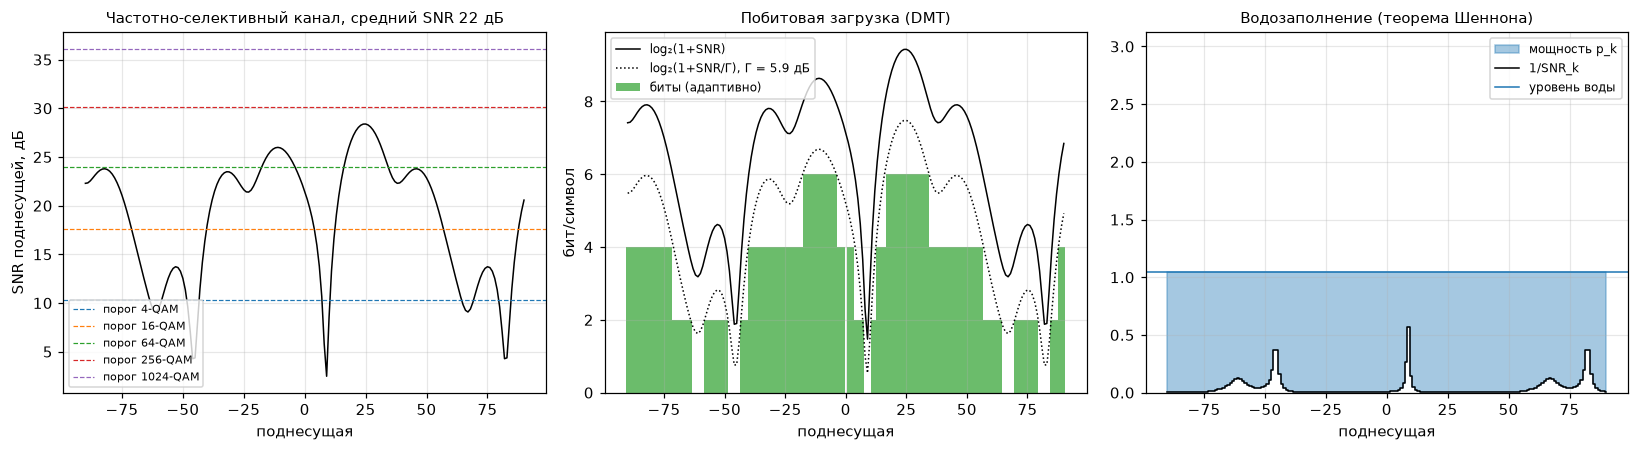

Пороги SNR для SER = 1e-03: 4-QAM 10.3 дБ, 16-QAM 17.6 дБ, 64-QAM 24.0 дБ, 256-QAM 30.1 дБ, 1024-QAM 36.1 дБ; зазор до Шеннона Γ ≈ 5.9 дБ
Бит на поднесущую: Шеннон (равная мощность) 6.27, водозаполнение 6.27, Шеннон с зазором 4.44, целочисленная загрузка 3.31
Адаптивная загрузка: SER измерено 7.01e-05 (цель ≤ 1e-03, теория 6.71e-05); выключено поднесущих: 23
  одна   4-QAM на всех: 2 бит, SER измерено 3.99e-03, теория 4.07e-03
  одна  16-QAM на всех: 4 бит, SER измерено 6.47e-02, теория 6.48e-02


  одна  64-QAM на всех: 6 бит, SER измерено 2.26e-01, теория 2.26e-01


In [8]:
SNR_DSL = 22          # средний SNR на поднесущую, дБ
PS_TGT = 1e-3         # целевая вероятность ошибки символа на каждой поднесущей
r6 = np.random.default_rng(7)
hd = np.arange(0, 16, 2); h6 = crandn(len(hd), r6) * np.exp(-hd / 6); h6 /= np.linalg.norm(h6)
H6 = np.zeros(N_FFT, complex); H6[hd] = h6; H6 = np.fft.fft(H6)[USED % N_FFT]
gk = 10 ** (SNR_DSL / 10) * np.abs(H6) ** 2 / np.mean(np.abs(H6) ** 2)

Q = lambda x: 0.5 * erfc(x / np.sqrt(2))
def ser_qam(Mq, g):
    p = 2 * (1 - 1 / np.sqrt(Mq)) * Q(np.sqrt(3 * g / (Mq - 1))); return 2 * p - p ** 2
MS = [4, 16, 64, 256, 1024]
g_req = {Mq: 10 ** (brentq(lambda d: np.log10(ser_qam(Mq, 10 ** (d / 10)) + 1e-300) - np.log10(PS_TGT), -5, 45) / 10) for Mq in MS}
gap = np.mean([10 * np.log10(g_req[Mq] / (Mq - 1)) for Mq in MS])

# загрузка: на каждой поднесущей — самая большая QAM, проходящая порог
Mk = np.array([max([0] + [Mq for Mq in MS if g >= g_req[Mq]]) for g in gk])
bk = np.where(Mk > 0, np.log2(np.maximum(Mk, 1)), 0)

def waterfill(g, Ptot):
    inv = np.sort(1 / g); n = len(g)
    for m in range(n, 0, -1):
        lvl = (Ptot + inv[:m].sum()) / m
        if lvl > inv[m - 1]: break
    return np.maximum(0, lvl - 1 / g), lvl
pw, lvl = waterfill(gk, len(gk))
C_flat = np.mean(np.log2(1 + gk)); C_wf = np.mean(np.log2(1 + pw * gk)); C_gap = np.mean(np.log2(1 + gk / 10 ** (gap / 10)))

# моделирование: адаптивная загрузка и одинаковая QAM на всех поднесущих
S6 = 3000
def run(Mvec):
    errs, tot = np.zeros(N_USED), np.zeros(N_USED)
    for k in np.where(Mvec > 0)[0]:
        c = qam_const(int(Mvec[k])); lab = r6.integers(0, len(c), S6)
        y = c[lab] + crandn(S6, r6) / np.sqrt(gk[k])
        errs[k] = np.sum(qam_demap(y, c) != lab); tot[k] = S6
    return errs, tot
ea, ta = run(Mk)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(USED, 10 * np.log10(gk), "k", lw=1)
for Mq, c in zip(MS, ("C0", "C1", "C2", "C3", "C4")):
    ax[0].axhline(10 * np.log10(g_req[Mq]), color=c, ls="--", lw=0.8, label=f"порог {Mq}-QAM")
ax[0].set_xlabel("поднесущая"); ax[0].set_ylabel("SNR поднесущей, дБ"); ax[0].legend(fontsize=7, loc="lower left")
ax[0].set_title(f"Частотно-селективный канал, средний SNR {SNR_DSL} дБ", fontsize=10)
ax[1].bar(USED, bk, width=1, color="C2", alpha=0.7, label="биты (адаптивно)")
ax[1].plot(USED, np.log2(1 + gk), "k", lw=1, label="log₂(1+SNR)")
ax[1].plot(USED, np.log2(1 + gk / 10 ** (gap / 10)), "k:", lw=1, label=f"log₂(1+SNR/Γ), Γ = {gap:.1f} дБ")
ax[1].set_xlabel("поднесущая"); ax[1].set_ylabel("бит/символ"); ax[1].legend(fontsize=8)
ax[1].set_title("Побитовая загрузка (DMT)", fontsize=10)
ax[2].fill_between(USED, 1 / gk, lvl, where=lvl > 1 / gk, color="C0", alpha=0.4, step="mid", label="мощность p_k")
ax[2].step(USED, 1 / gk, "k", lw=1, where="mid", label="1/SNR_k"); ax[2].axhline(lvl, color="C0", lw=1, label="уровень воды")
ax[2].set_ylim(0, 3 * lvl); ax[2].set_xlabel("поднесущая"); ax[2].legend(fontsize=8)
ax[2].set_title("Водозаполнение (теорема Шеннона)", fontsize=10)
plt.tight_layout(); plt.show()

print(f"Пороги SNR для SER = {PS_TGT:.0e}: " + ", ".join(f"{Mq}-QAM {10*np.log10(g_req[Mq]):.1f} дБ" for Mq in MS) + f"; зазор до Шеннона Γ ≈ {gap:.1f} дБ")
print(f"Бит на поднесущую: Шеннон (равная мощность) {C_flat:.2f}, водозаполнение {C_wf:.2f}, Шеннон с зазором {C_gap:.2f}, целочисленная загрузка {bk.mean():.2f}")
print(f"Адаптивная загрузка: SER измерено {ea.sum()/ta.sum():.2e} (цель ≤ {PS_TGT:.0e}, теория {np.sum([ser_qam(Mk[k], gk[k]) for k in range(N_USED) if Mk[k]])/np.sum(Mk>0):.2e}); выключено поднесущих: {np.sum(Mk == 0)}")
for Mq in (4, 16, 64):
    ef, tf = run(np.full(N_USED, Mq))
    print(f"  одна {Mq:3d}-QAM на всех: {np.log2(Mq):.0f} бит, SER измерено {ef.sum()/tf.sum():.2e}, теория {np.mean(ser_qam(Mq, gk)):.2e}")

## 7. Нумерология: какой $\Delta f$ выбрать
При фиксированной доле CP (в NR ≈ 7 %) выбор $\Delta f=15\cdot2^\mu$ кГц — компромисс двух помех:
* **ICI от доплера** растёт с $f_D/\Delta f$: полезная часть ослабляется на коэффициент когерентности окна $\frac1{N^2}\sum_d(N-|d|)J_0(2\pi f_Dd/F_s)\approx1-\frac{(\pi f_DT)^2}{3}$ (модель Джейкса);
* **ISI от лучей длиннее CP** растёт с $\Delta f$, потому что $T_{CP}=0.07/\Delta f$ укорачивается; для луча с превышением $D$ отсчётов — формула раздела 1.

Теория (линии) собирает обе части по экспоненциальному профилю задержек. Моделирование (точки) — честный изменяющийся во времени канал с суммой синусоид на каждом луче; разброс ±1 дБ — конечное число реализаций.

* **Пешеход в городе** — доплер ничтожен, всё решает разброс задержек: лучший $\mu=0$, а на $\mu=4$ CP 0.3 мкс короче профиля, SIR 9 дБ. Поэтому FR1 (до 6 ГГц) использует 15/30 кГц, а для больших сот — расширенный CP.
* **Скоростной поезд** 500 км/ч — доплер 1.85 кГц. На 15 кГц SIR всего 16 дБ (потолок для 64-QAM), оптимум на 120 кГц, где ещё хватает CP.
* **FR2, 28 ГГц** — доплер 3 кГц при коротком профиле: чем шире поднесущие, тем лучше; NR использует там 120 кГц. Плюс фазовый шум из раздела 4: генератор 28 ГГц с $\beta=1$ кГц даёт ICI −11.6 дБ на 15 кГц и −20.6 дБ на 120 кГц.

Это и есть причина гибкой нумерологии NR: одна форма сигнала, а $\Delta f$ подбирается под диапазон и сценарий. OTFS (`otfs_sim`) идёт другим путём: вместо подбора $\Delta f$ так, чтобы доплер был мал, он делает доплер частью модели канала.

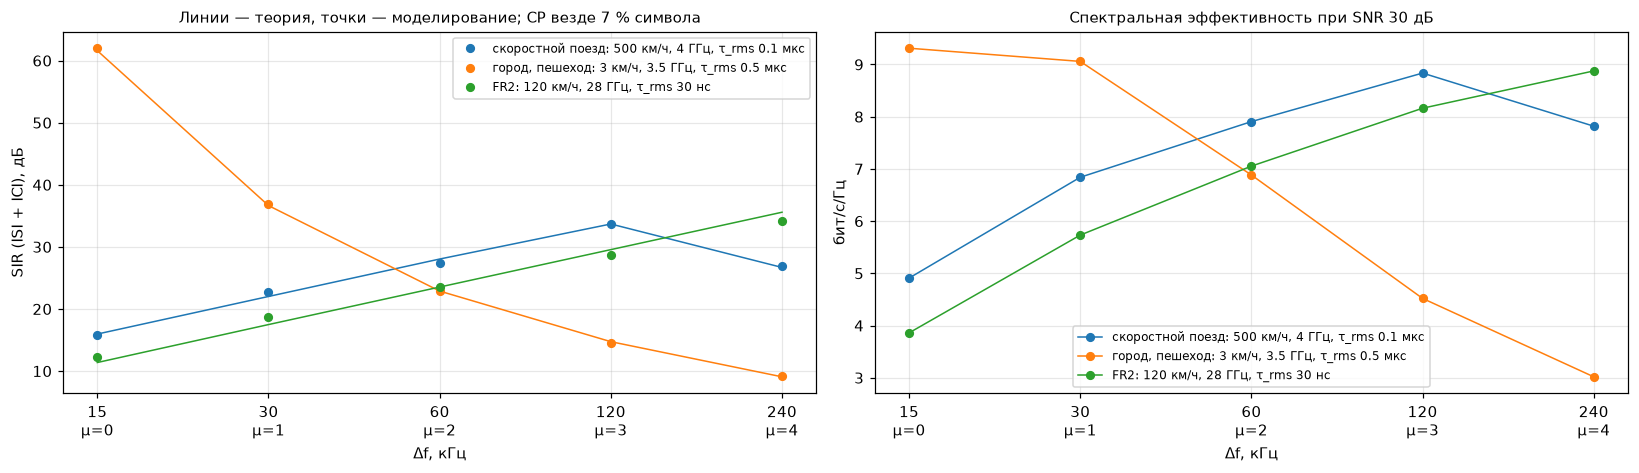

Моделирование: 15 с
скоростной поезд: 500 км/ч, 4 ГГц, τ_rms 0.1 мкс: f_D = 1852 Гц; SIR 15.9 / 22.8 / 27.3 / 33.7 / 26.9 dB (теория 16.0 / 22.0 / 28.0 / 33.7 / 26.7); лучший Δf = 120 кГц
город, пешеход: 3 км/ч, 3.5 ГГц, τ_rms 0.5 мкс: f_D = 10 Гц; SIR 62.0 / 36.8 / 22.9 / 14.5 / 9.3 dB (теория 61.6 / 36.7 / 22.9 / 14.7 / 9.1); лучший Δf = 15 кГц
FR2: 120 км/ч, 28 ГГц, τ_rms 30 нс: f_D = 3111 Гц; SIR 12.3 / 18.7 / 23.6 / 28.7 / 34.2 dB (теория 11.4 / 17.5 / 23.5 / 29.6 / 35.6); лучший Δf = 240 кГц
Фазовый шум генератора 28 ГГц с β = 1 кГц, ICI после снятия CPE ≈ πβ/(3Δf): μ=0: -11.6 dB, μ=1: -14.6 dB, μ=2: -17.6 dB, μ=3: -20.6 dB, μ=4: -23.6 dB


In [9]:
FS7, N0_7, CP0_7 = 30.72e6, 2048, 144            # NR: 30.72 МГц, μ = 0 → FFT 2048, CP 144
MUS = np.arange(5)
SNR7 = 30
SCEN = [("скоростной поезд: 500 км/ч, 4 ГГц, τ_rms 0.1 мкс", 500 / 3.6 * 4e9 / 3e8, 0.1e-6),
        ("город, пешеход: 3 км/ч, 3.5 ГГц, τ_rms 0.5 мкс", 3 / 3.6 * 3.5e9 / 3e8, 0.5e-6),
        ("FR2: 120 км/ч, 28 ГГц, τ_rms 30 нс", 120 / 3.6 * 28e9 / 3e8, 30e-9)]

def pdp_taps(tau):
    ts = tau * FS7; step = max(1, int(round(ts / 8)))
    d = np.arange(0, int(8 * ts) + 1, step); p = np.exp(-d / ts); return d, p / p.sum()

def coh(V, fd):
    d = np.arange(-(V - 1), V); return np.sum((V - np.abs(d)) * j0(2 * np.pi * fd * d / FS7)) / V ** 2

def sir_sim(mu, fd, tau, R, rng, K=16):
    N, Ncp = N0_7 >> mu, CP0_7 >> mu; L = N + Ncp
    d, p = pdp_taps(tau); S = 3; ns = S * L
    Sp = Ip = 0.0; t = np.arange(ns) / FS7
    for _ in range(R):
        th = rng.uniform(0, 2 * np.pi, (len(d), K, 1)); ph = rng.uniform(0, 2 * np.pi, (len(d), K, 1))
        a = np.exp(1j * (2 * np.pi * fd * np.cos(th) * t + ph)).sum(1) / np.sqrt(K) * np.sqrt(p)[:, None]
        X = QPSK[rng.integers(0, 4, (S, N))]; x = ofdm_mod(X, n=N, ncp=Ncp, bins=np.arange(N)).ravel()
        y = np.zeros(ns, complex)
        for i in range(len(d)):
            y[d[i]:] += a[i, d[i]:] * x[:ns - d[i]]
        for s in (1, 2):
            w0 = s * L + Ncp; n = np.arange(w0, w0 + N)
            Y = np.fft.fft(y[n]) / np.sqrt(N)
            valid = (n[None] - d[:, None]) >= s * L                     # отсчёт луча пришёл из своего символа
            coef = np.sum(a[:, n] * valid, 1) / N
            Dk = np.exp(-2j * np.pi * np.outer(np.arange(N), d) / N) @ coef
            Sp += np.sum(np.abs(Dk * X[s]) ** 2); Ip += np.sum(np.abs(Y - Dk * X[s]) ** 2)
    return Sp / Ip

def sir_th(mu, fd, tau):
    N, Ncp = N0_7 >> mu, CP0_7 >> mu
    d, p = pdp_taps(tau); V = N - np.maximum(0, d - Ncp)
    cv = {v: coh(v, fd) for v in np.unique(V)}
    S = np.sum(p * np.array([cv[v] for v in V]) * (V / N) ** 2)
    return S / (1 - S)

t0 = time.time()
r7 = np.random.default_rng(11)
res7 = {nm: (np.array([sir_th(m, fd, tau) for m in MUS]), np.array([sir_sim(m, fd, tau, 24, r7) for m in MUS])) for nm, fd, tau in SCEN}
dfk = 15 * 2 ** MUS
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
n0 = 10 ** (-SNR7 / 10)
for (nm, (th, me)), c in zip(res7.items(), ("C0", "C1", "C2")):
    ax[0].plot(dfk, 10 * np.log10(th), c + "-", lw=1); ax[0].plot(dfk, 10 * np.log10(me), c + "o", ms=5, label=nm)
    se = np.log2(1 + 1 / (1 / me + n0)) * N0_7 / (N0_7 + CP0_7)
    ax[1].plot(dfk, se, c + "o-", ms=5, lw=1, label=nm)
for a in ax:
    a.set_xscale("log", base=2); a.set_xticks(dfk); a.set_xticklabels([f"{v}\nμ={m}" for v, m in zip(dfk, MUS)]); a.set_xlabel("Δf, кГц")
ax[0].set_ylabel("SIR (ISI + ICI), дБ"); ax[0].legend(fontsize=8)
ax[0].set_title("Линии — теория, точки — моделирование; CP везде 7 % символа", fontsize=10)
ax[1].set_ylabel("бит/с/Гц"); ax[1].legend(fontsize=8)
ax[1].set_title(f"Спектральная эффективность при SNR {SNR7} дБ", fontsize=10)
plt.tight_layout(); plt.show()

print(f"Моделирование: {time.time()-t0:.0f} с")
for nm, fd, tau in SCEN:
    th, me = res7[nm]
    print(f"{nm}: f_D = {fd:.0f} Гц; SIR " + " / ".join(f"{10*np.log10(v):.1f}" for v in me) + f" dB (теория " + " / ".join(f"{10*np.log10(v):.1f}" for v in th) + f"); лучший Δf = {dfk[np.argmax(me)]} кГц")
# фазовый шум (раздел 4) толкает FR2 к большим Δf ещё сильнее
BETA_FR2 = 1e3
print(f"Фазовый шум генератора 28 ГГц с β = {BETA_FR2/1e3:.0f} кГц, ICI после снятия CPE ≈ πβ/(3Δf): " + ", ".join(f"μ={m}: {10*np.log10(np.pi*BETA_FR2/(3*v*1e3)):.1f} dB" for m, v in zip(MUS, dfk)))

## OFDM в реальных системах и место в серии

| Система | $\Delta f$ | FFT | CP | Что адаптируется | Особенность |
|---|---|---|---|---|---|
| Wi-Fi 802.11a/g/n/ac | 312.5 кГц | 64…512 | 0.8 мкс (25 %) | MCS на весь пакет | преамбула Шмидла–Кокса (раздел 3), 4–16 пилотов на CPE |
| Wi-Fi 6/7 (ax/be) | 78.125 кГц | 256…4096 | 0.8/1.6/3.2 мкс | MCS, OFDMA | 4096-QAM: нужны IRR > 40 дБ и чистый генератор (раздел 4) |
| LTE | 15 кГц | 128…2048 | 4.7 мкс (7 %) | MCS по блокам ресурсов | SC-FDMA на аплинке из-за PAPR (раздел 5, `lte_sim`) |
| 5G NR | 15·2^μ кГц | до 4096 | 7 % (+ расширенный при μ=2) | MCS, BWP, нумерология | гибкий $\Delta f$ (раздел 7), PT-RS против фазового шума |
| DVB-T2 | 0.28…4.5 кГц | 1k…32k | 1/128…1/4 | — (вещание) | огромный FFT ради одночастотных сетей с задержками в сотни мкс |
| DAB | 1 кГц | 2048 | 246 мкс | — | дифференциальная QPSK, без оценки канала |
| ADSL/VDSL2 | 4.3125 кГц | 512…8192 | — | **биты на поднесущую** (раздел 6) | DMT: вещественный сигнал (эрмитова симметрия), загрузка до 15 бит |
| DJI DroneID | 15 кГц | 1024 | LTE-подобный | — | `ocusync_sim`: синхронизация с нуля по ZC |

**Что OFDM покупает и чем платит.** Покупает эквалайзер в одно деление на поднесущую при любой длине канала до CP, гибкое распределение частот (OFDMA, загрузка, пилоты в любой клетке сетки) и простой MIMO на поднесущей. Платит:
- полосой: CP и защитные поднесущие, 7–30 %;
- чувствительностью к частоте и фазе: разделы 3–4;
- пик-фактором: раздел 5;
- отсутствием разнесения без кода: раздел 6, `lte_sim`.

**Куда ведёт серия.**
- **SC-FDE и OCDM** (`ocdm_sim`): то же «одно деление», но символ размазан по всем поднесущим. Разнесение есть без кода, PAPR ниже.
- **OTFS, Zak-OTFS, AFDM, OTSM/ODDM** (`otfs_sim` и следующие): сетка задержка–доплер вместо время–частота. Доплер из помехи (раздел 7) становится частью канала, цена — более сложный приёмник.
- **LoRa и CDMA** (`lora_sim`, `cdma_sim`): одна несущая с расширением спектра. Нет ни ICI, ни пик-фактора, но и спектральная эффективность на порядок ниже.

## Что покрутить
- `N_CP = 4` — в разделе 1 плато сжимается до нуля: канал длиной 6 отсчётов уже не помещается, EVM растёт даже при идеальном окне.
- `W_WOLA = 12` (раздел 2) — ACLR ещё ниже, но на канал остаётся 6 отсчётов CP; `W_WOLA = 1` — почти чистый CP-OFDM.
- `N_USED = 240` — защитных поднесущих почти нет: ACLR CP-OFDM заметно ухудшается, и без WOLA/фильтра маску не выполнить.
- `EPS = 1.2` в разделе 3 — фаза $P$ сворачивается через ±π: дробная оценка даёт −0.8. Нужна целая часть из второго символа.
- `G_IQ, PH_IQ = 1.0, np.deg2rad(10)` — чистая неортогональность ветвей; IRR падает до ~21 дБ.
- `P_RAPP = 10` — почти идеальный ограничитель: EVM и ACLR падают круче, и клиппинг с фильтрацией выигрывает больше.
- `CR = 1.4` — PAPR ниже 6 дБ, но клиппинг сам по себе даёт EVM около −18 дБ.
- `SNR_DSL = 35`, `PS_TGT = 1e-7` — режим ADSL: больше бит, но зазор $\Gamma$ растёт до ~9.8 дБ.
- В разделе 7 замените $\tau_{rms}$ пешехода на `2e-6` — даже $\mu=0$ не спасает, нужен расширенный CP.